# When does air move toward M1M3 at the TMA top ring? (wind_vs_sonic v3)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-05  
**Last Modified:** 2026-11-05  
**Status:** In Progress  
**Keywords:** wind, sonic anemometer, ESS airTurbulence, dome, TMA top ring, into-the-wind, altitude  

## Description
Maps the airflow at the four top-ring sonic anemometers (ESS salIndex 123 to 126) against
outside wind speed, pointing relative to the wind and altitude, to find when air moves
toward the M1M3 mirror.

- **Axis 2 is the optical axis; positive axis 2 is air moving away from M1M3** (Elana).
  "Toward M1M3" means axis-2 mean below `TOWARD_CUT` = -0.3 m/s.
- Axes 0 and 1 are the sensors' own axes; their directions are not yet known.
- `into_wind_deg` = wind_dir - TMA azimuth, wrapped to ±180 deg; 0 = pointing into the wind.
  Dome azimuth is not used yet: the dome is assumed to track the TMA.
- Outside wind in the telescope frame, assuming horizontal wind of speed U [m/s] entering
  the slit (air moves toward wind_dir + 180 deg):
  - `u_ax` = -U cos(into_wind) cos(alt): along the optical axis, positive away from M1M3,
    the same sign convention as sonic axis 2;
  - `u_el` = U cos(into_wind) sin(alt): along increasing elevation, perpendicular to the
    optical axis;
  - `u_az` = -U sin(into_wind): horizontal, along increasing azimuth.
- Louvers: `louvers_n_open` (count more than 50 % open). In this period no exposure has
  more than 6 open; states compared are 0, 5 and 6.

On-sky exposures (`img_type` science, acq, cwfs), 20260120 to 20260714 (the sonic data
start 20260120; observing stopped after 20260714 until 20261027).

**Output:** one PDF, `wind_vs_sonic_v3.pdf`, in the study run directory.  
**References:** `value_added/docs/schema.md` (`sonic`, `wind_derived`, `louvers` groups);
`wind_vs_sonic_v2.ipynb`.


## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-05 | Aaron Roodman | Initial version: heat maps, toward-M1M3 probability, bimodality, mirror test, 3x3 coefficients |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Analysis](#analysis)
6. [Results & Plots](#results)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS_MIN, DAY_OBS_MAX = 20260120, 20260714
IMG_TYPES = ('science', 'acq', 'cwfs')
SONICS = (123, 124, 125, 126)          # TMA top ring
TOWARD_CUT = -0.3                      # axis-2 mean below this = toward M1M3 [m/s]
WIND_MIN = 6.0                         # outside wind cut for the maps [m/s]
ANGLE_STEP = 15                        # into_wind_deg bin width [deg]
ALT_STEP = 5                           # altitude bin width for heat maps [deg]
U_EDGES = [0, 1.5, 3, 4.5, 6, 7.5, 9, 10.5, 12, 15]   # outside wind bins [m/s]
ALT_SPLIT = 50                         # low/high altitude split for the onset maps [deg]
ALT_BANDS = [(15, 45), (45, 65), (65, 90)]            # bands for the bimodality pages [deg]
MIN_CELL = 20                          # minimum exposures per heat-map cell
NIGHT_MIN = 50                         # minimum windy exposures for a per-night fit
LOUVER_STATES = [(-0.5, 0.5, '0 open'), (4.5, 5.5, '5 open'), (5.5, 6.5, '6 open')]

run = study_run('airflow/airflow_correlations', 'wind_vs_sonic_v3')
PDF = run.path / 'wind_vs_sonic_v3.pdf'

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from scipy import stats

from rubinwork.products.value_added import reader
from rubinwork.common.telemetry_clients import make_consdb_client
from rubinwork.common.utils import nmad

<a id='functions'></a>
## Helper Functions

In [3]:
def binned_median(x, y, edges, nmin=MIN_CELL):
    """Median and count of y in bins of x; NaN where fewer than nmin."""
    ok = np.isfinite(x) & np.isfinite(y)
    med = stats.binned_statistic(x[ok], y[ok], 'median', bins=edges).statistic
    n = np.histogram(x[ok], edges)[0]
    med[n < nmin] = np.nan
    return 0.5 * (edges[1:] + edges[:-1]), med, n


def map2d(x, y, z, xe, ye, stat='median', nmin=MIN_CELL):
    """2D binned statistic of z, NaN where a cell has fewer than nmin values."""
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(z)
    s = stats.binned_statistic_2d(x[ok], y[ok], z[ok], stat, bins=[xe, ye]).statistic
    n = np.histogram2d(x[ok], y[ok], [xe, ye])[0]
    s[n < nmin] = np.nan
    return s.T, n.T


def huber(X, y):
    """Huber RLM of y on the columns of X plus a constant; None if under 30 points."""
    X = np.atleast_2d(np.asarray(X, float).T).T if np.ndim(X) == 1 else np.asarray(X, float)
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    if ok.sum() < 30:
        return None
    return sm.RLM(y[ok], sm.add_constant(X[ok], has_constant='add'),
                  M=sm.robust.norms.HuberT()).fit()


def text_page(pdf, title, body):
    """One PDF page of monospace text."""
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.03, 0.96, title, fontsize=12, va='top')
    fig.text(0.03, 0.91, body, family='monospace', fontsize=7.5, va='top')
    pdf.savefig(fig); plt.show()


def four_panel(title):
    fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
    fig.suptitle(title, fontsize=11)
    return fig, axs

<a id='data'></a>
## Data Access

In [4]:
con = reader.open_db()
cols = ['visit_id', 'day_obs', 'wind_speed_ms', 'wind_dir_deg', 'azimuth_deg',
        'into_wind_deg', 'louvers_n_open', 'louvers_open_names']
for i in SONICS:
    cols += [f'sonic{i}_mean_{a}_ms' for a in range(3)] + [f'sonic{i}_rms_2_ms']
vt = con.sql(f"select {', '.join(cols)} from visit_telemetry "
             f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").df()
ex = make_consdb_client().query(
    f"select exposure_id as visit_id, img_type, altitude from cdb_lsstcam.exposure "
    f"where day_obs between {DAY_OBS_MIN} and {DAY_OBS_MAX}").to_pandas()
d = vt.merge(ex, on='visit_id', how='inner')
d['altitude'] = pd.to_numeric(d['altitude'], errors='coerce')
d = d[d.img_type.isin(IMG_TYPES) & d.altitude.notna() & d.wind_speed_ms.notna()
      & d.into_wind_deg.notna()].copy()
th, alt, U = np.radians(d.into_wind_deg), np.radians(d.altitude), d.wind_speed_ms
d['u_par'] = U * np.cos(th)
d['u_ax'] = -U * np.cos(th) * np.cos(alt)
d['u_el'] = U * np.cos(th) * np.sin(alt)
d['u_az'] = -U * np.sin(th)
d['louver_state'] = None
for lo, hi, lab in LOUVER_STATES:
    d.loc[(d.louvers_n_open > lo) & (d.louvers_n_open <= hi), 'louver_state'] = lab
w = d[d.wind_speed_ms >= WIND_MIN]
print(f'{len(d)} on-sky exposures, {d.day_obs.nunique()} nights, {d.day_obs.min()} to '
      f'{d.day_obs.max()}; {len(w)} with outside wind >= {WIND_MIN} m/s on '
      f'{w.day_obs.nunique()} nights')
print('louver states:', d.louver_state.value_counts(dropna=False).to_dict())

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


70454 on-sky exposures, 111 nights, 20260127 to 20260714; 25741 with outside wind >= 6.0 m/s on 82 nights
louver states: {'6 open': 66800, '5 open': 1944, '0 open': 1536, None: 174}


<a id='analysis'></a>
## Analysis

Summary per sonic, outside wind ≥ `WIND_MIN`: fraction toward M1M3, and axis-2 against `u_ax` and `u_par` (Huber, Pearson, Spearman).

In [5]:
rows = []
for i in SONICS:
    y = w[f'sonic{i}_mean_2_ms'].to_numpy()
    r = dict(sonic=i, n=int(np.isfinite(y).sum()),
             frac_toward=np.mean(y[np.isfinite(y)] < TOWARD_CUT))
    for xn in ('u_ax', 'u_par'):
        x = w[xn].to_numpy(); ok = np.isfinite(x) & np.isfinite(y)
        f = huber(x, y)
        r[f'slope_{xn}'] = f.params[1]; r[f'err_{xn}'] = f.bse[1]
        r[f'r_{xn}'] = stats.pearsonr(x[ok], y[ok])[0]
        r[f'rho_{xn}'] = stats.spearmanr(x[ok], y[ok])[0]
    rows.append(r)
summary = pd.DataFrame(rows).set_index('sonic')
display(summary.round(3))

# Asymmetric slopes: Huber of axis 2 on u_ax separately for u_ax > 0 and < 0, by altitude band
arows = []
for i in SONICS:
    for lo, hi in [(15, 90)] + ALT_BANDS:
        s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
        for sgn, lab in ((1, 'u_ax>0 (wind pushes away from M1M3)'),
                         (-1, 'u_ax<0 (wind pushes toward M1M3)')):
            t = s_[sgn * s_.u_ax > 0]
            f = huber(t.u_ax.to_numpy(), t[f'sonic{i}_mean_2_ms'].to_numpy())
            if f is None:
                continue
            arows.append(dict(sonic=i, alt=f'{lo}-{hi}', half=lab[:6], n=int(f.nobs),
                              intercept_ms=f.params[0], slope=f.params[1], slope_err=f.bse[1]))
asym = pd.DataFrame(arows)
display(asym.pivot_table(index=['sonic', 'alt'], columns='half', values='slope').round(3))

# Per-night fits and the near-zero population
nrows = []
for (night, g) in w.groupby('day_obs'):
    if len(g) < NIGHT_MIN:
        continue
    r = dict(day_obs=night, n=len(g), louvers=g.louvers_n_open.median(),
             wind=g.wind_speed_ms.median())
    strong = g[np.abs(g.u_ax) > 3]
    for i in SONICS:
        y = g[f'sonic{i}_mean_2_ms'].to_numpy()
        f = huber(g.u_ax.to_numpy(), y)
        r[f'slope{i}'] = f.params[1] if f is not None else np.nan
        r[f'err{i}'] = f.bse[1] if f is not None else np.nan
        ys = strong[f'sonic{i}_mean_2_ms'].dropna()
        r[f'zero{i}'] = np.mean(np.abs(ys) < 0.1) if len(ys) >= 10 else np.nan
    nrows.append(r)
nights = pd.DataFrame(nrows)
print(f'{len(nights)} nights with >= {NIGHT_MIN} exposures at wind >= {WIND_MIN} m/s')

# 3x3 coefficients: each sensor axis on (u_ax, u_el, u_az), all exposures
crows = []
for i in SONICS:
    for a in range(3):
        f = huber(d[['u_ax', 'u_el', 'u_az']].to_numpy(), d[f'sonic{i}_mean_{a}_ms'].to_numpy())
        crows.append(dict(sonic=i, axis=a, n=int(f.nobs), const_ms=f.params[0],
                          **{f'c_{k}': f.params[j + 1] for j, k in enumerate(('ax', 'el', 'az'))},
                          **{f'e_{k}': f.bse[j + 1] for j, k in enumerate(('ax', 'el', 'az'))},
                          resid_nmad_ms=nmad(f.resid)))
coef = pd.DataFrame(crows).set_index(['sonic', 'axis'])
display(coef.round(3))

,n,frac_toward,slope_u_ax,err_u_ax,r_u_ax,rho_u_ax,slope_u_par,err_u_par,r_u_par,rho_u_par
sonic,,,,,,,,,,
123,25741,0.030,-0.062,0.001,-0.295,-0.393,0.034,0.000,0.319,0.426
124,25740,0.111,0.010,0.001,0.139,0.053,-0.002,0.000,-0.103,0.003
125,25740,0.230,0.127,0.001,0.571,0.530,-0.058,0.001,-0.537,-0.522
126,25741,0.069,-0.010,0.001,0.064,-0.060,0.006,0.000,-0.063,0.043


half         u_ax<0  u_ax>0
sonic alt                  
123   15-45  -0.058   0.009
      15-90  -0.121  -0.017
      45-65  -0.122  -0.025
      65-90  -0.229  -0.053
124   15-45   0.036   0.011
      15-90   0.022  -0.005
      45-65   0.035  -0.010
      65-90  -0.026  -0.046
125   15-45   0.174   0.072
      15-90   0.163   0.128
      45-65   0.166   0.171
      65-90   0.158   0.091
126   15-45  -0.051   0.019
      15-90  -0.057   0.040
      45-65  -0.049   0.043
      65-90  -0.167   0.159

62 nights with >= 50 exposures at wind >= 6.0 m/s


n  const_ms   c_ax   c_el   c_az   e_ax   e_el   e_az  \
sonic axis                                                              
123   0     69284    -0.088 -0.009 -0.015  0.002  0.001  0.000  0.000   
      1     69284     0.026 -0.016 -0.011  0.012  0.001  0.001  0.000   
      2     69284     0.230  0.017  0.037 -0.049  0.001  0.001  0.000   
124   0     69282    -0.132 -0.051 -0.046  0.020  0.001  0.001  0.000   
      1     69282     0.228  0.110  0.155 -0.031  0.002  0.001  0.001   
      2     69282     0.085  0.038  0.013  0.006  0.002  0.001  0.000   
125   0     69741     0.194  0.001  0.078 -0.017  0.002  0.001  0.001   
      1     69741     0.234 -0.009  0.118 -0.059  0.002  0.001  0.001   
      2     69741     0.017  0.117 -0.005  0.033  0.002  0.001  0.000   
126   0     69743    -0.026 -0.011 -0.006  0.006  0.001  0.001  0.000   
      1     69743    -0.137  0.001 -0.034 -0.021  0.001  0.001  0.000   
      2     69743     0.144  0.018  0.011 -0.024  0.001  0.001  0.000   

            resid_nmad_ms  
sonic axis                 
123   0             0.129  
      1             0.266  
      2             0.285  
124   0             0.210  
      1             0.472  
      2             0.321  
125   0             0.416  
      1             0.459  
      2             0.336  
126   0             0.198  
      1             0.288  
      2             0.316

<a id='results'></a>
## Results & Plots

<Figure size 1100x850 with 0 Axes>

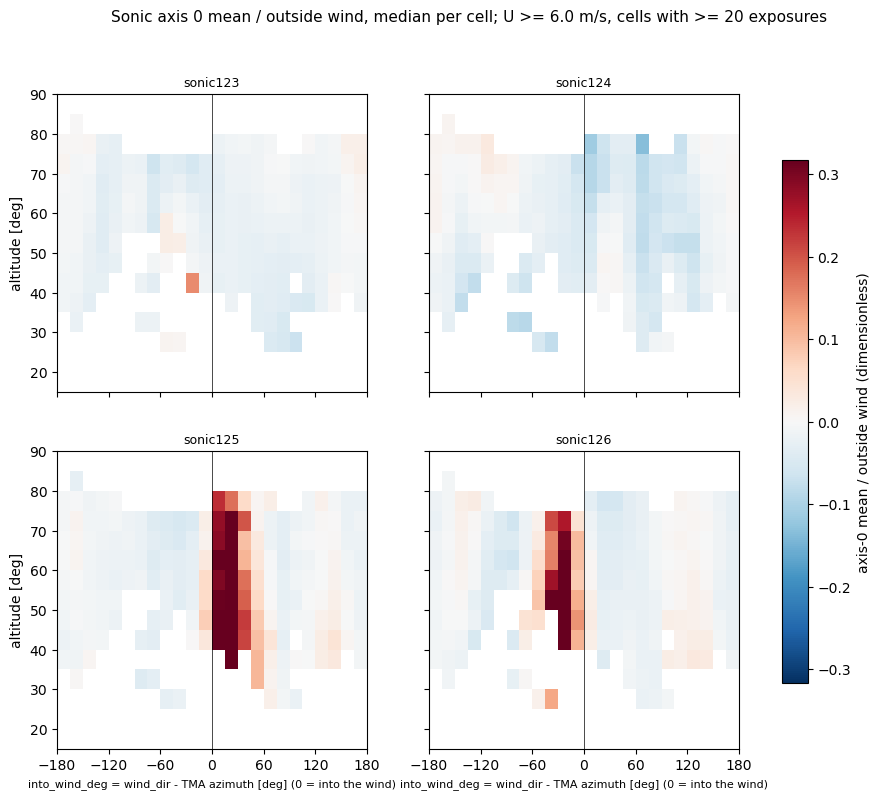

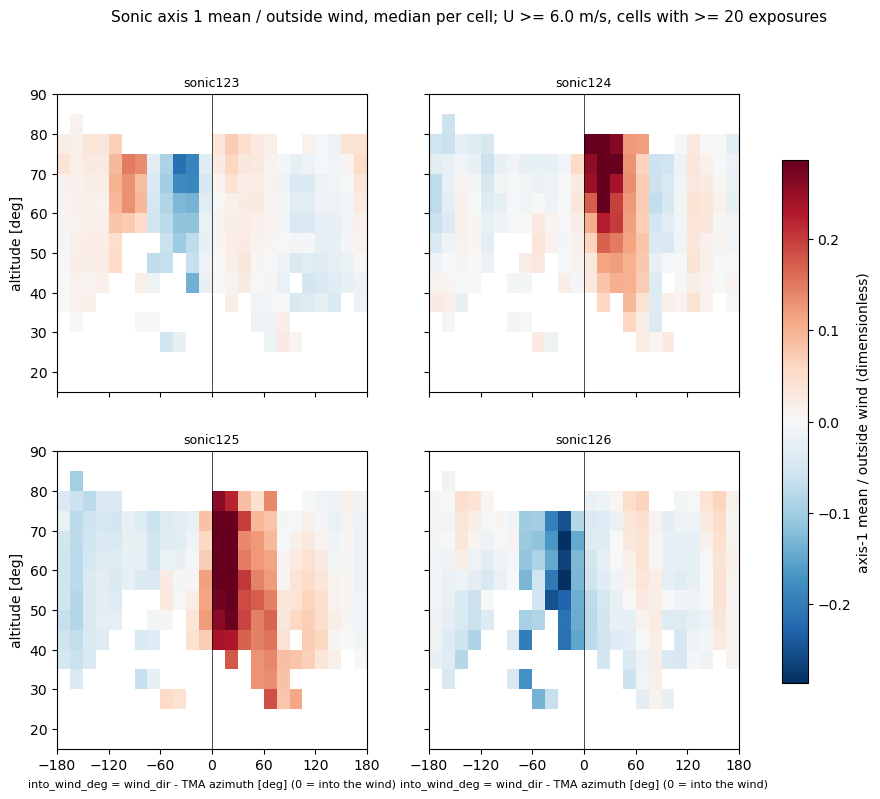

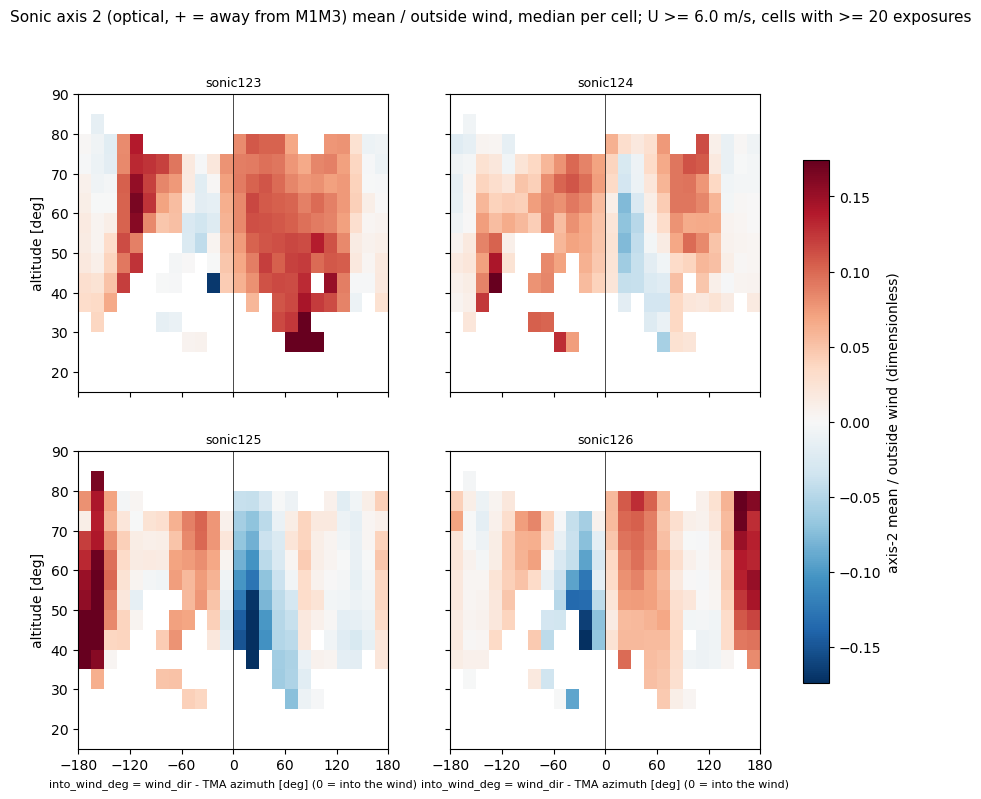

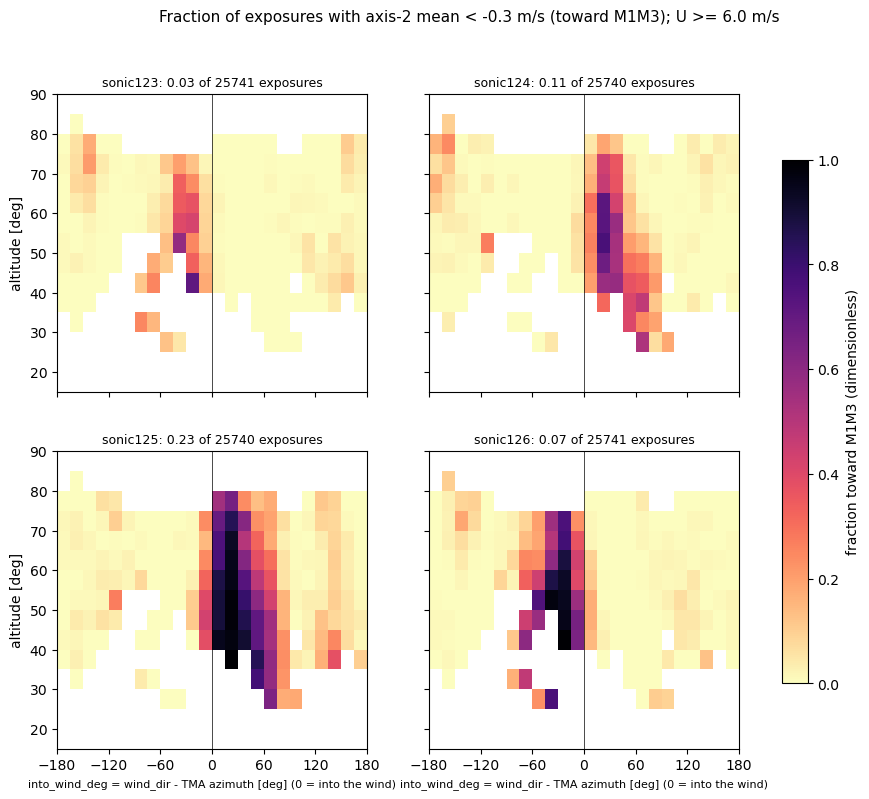

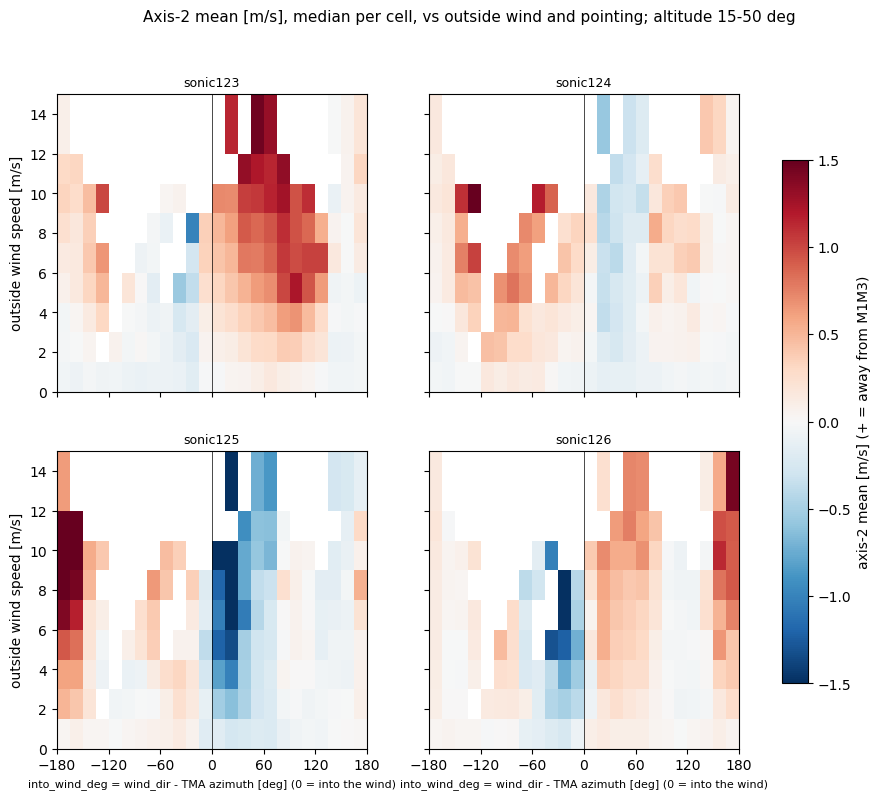

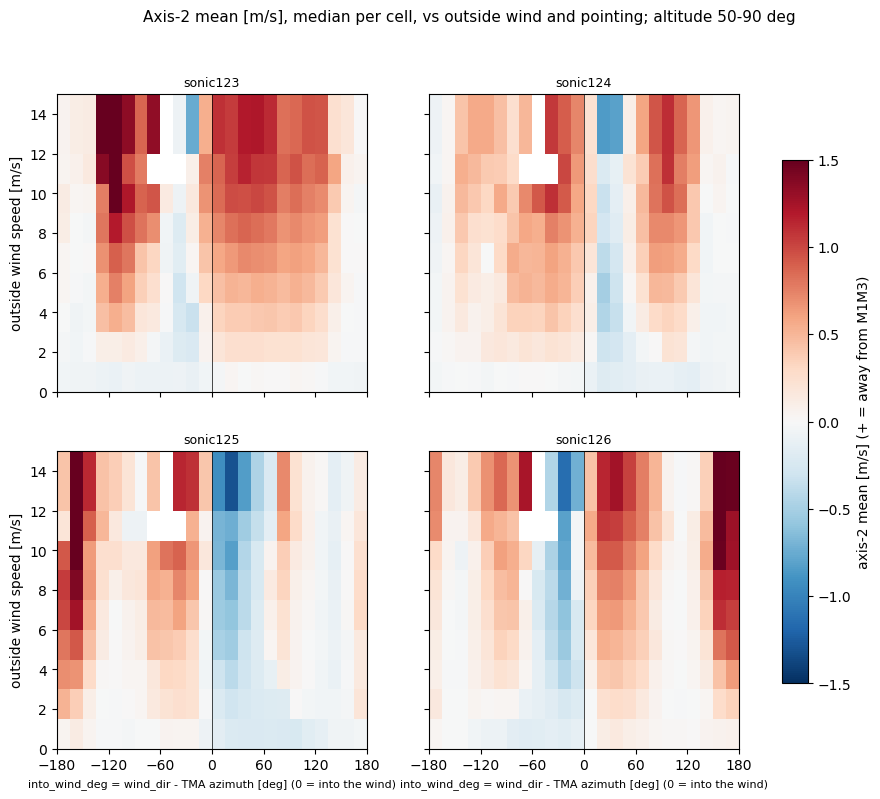

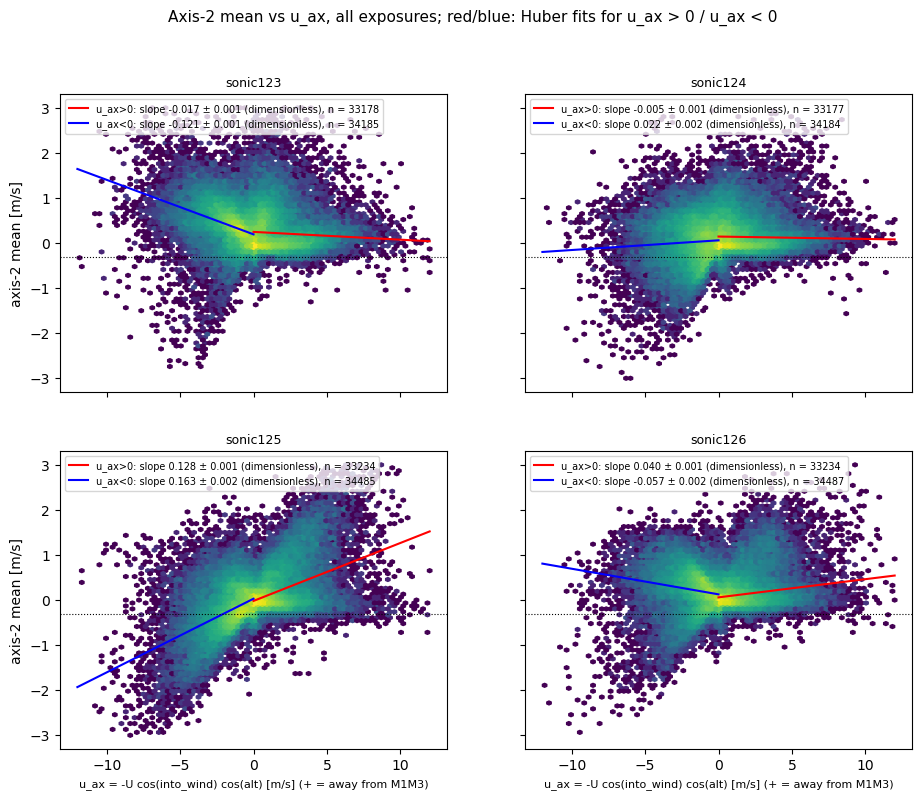

<Figure size 1100x850 with 0 Axes>

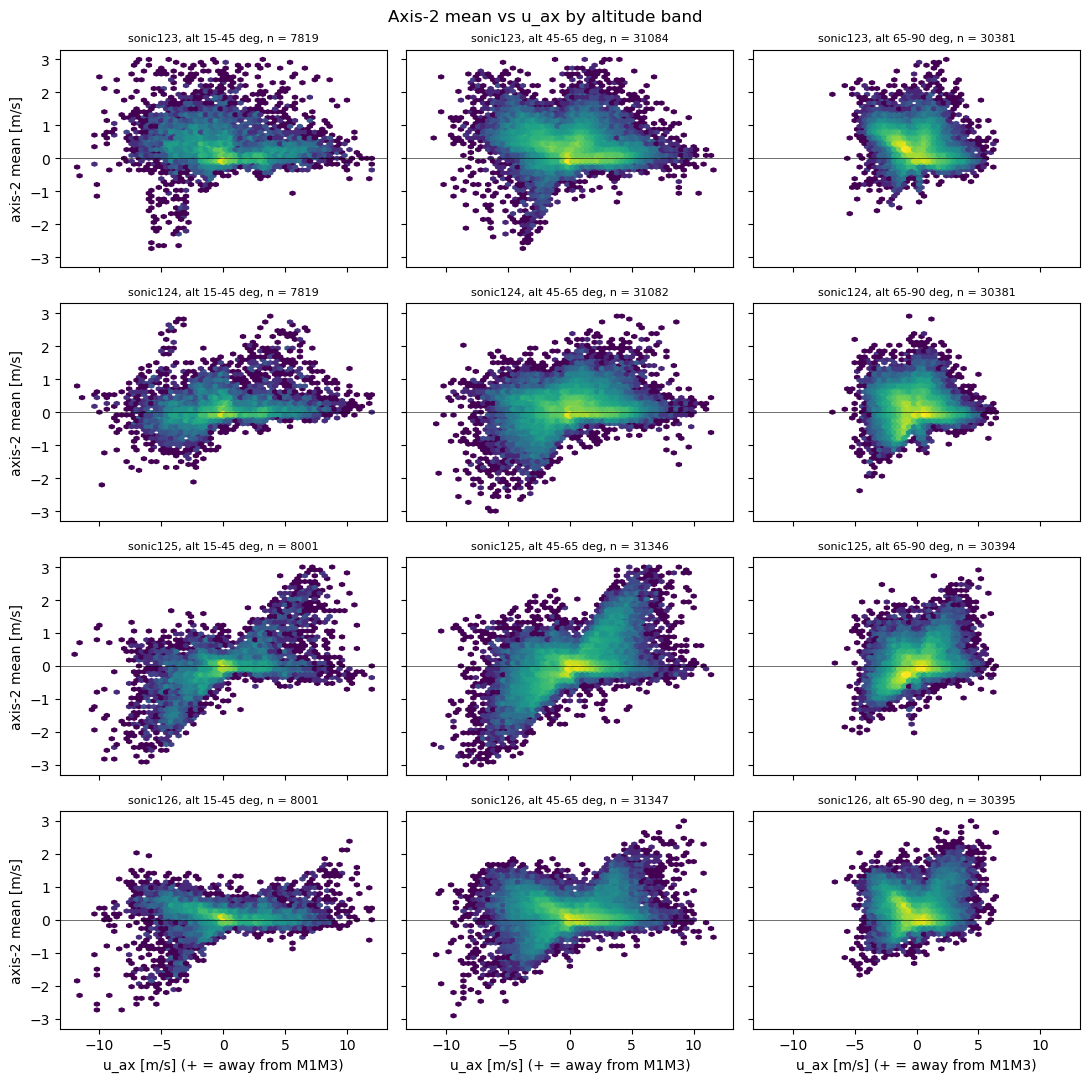

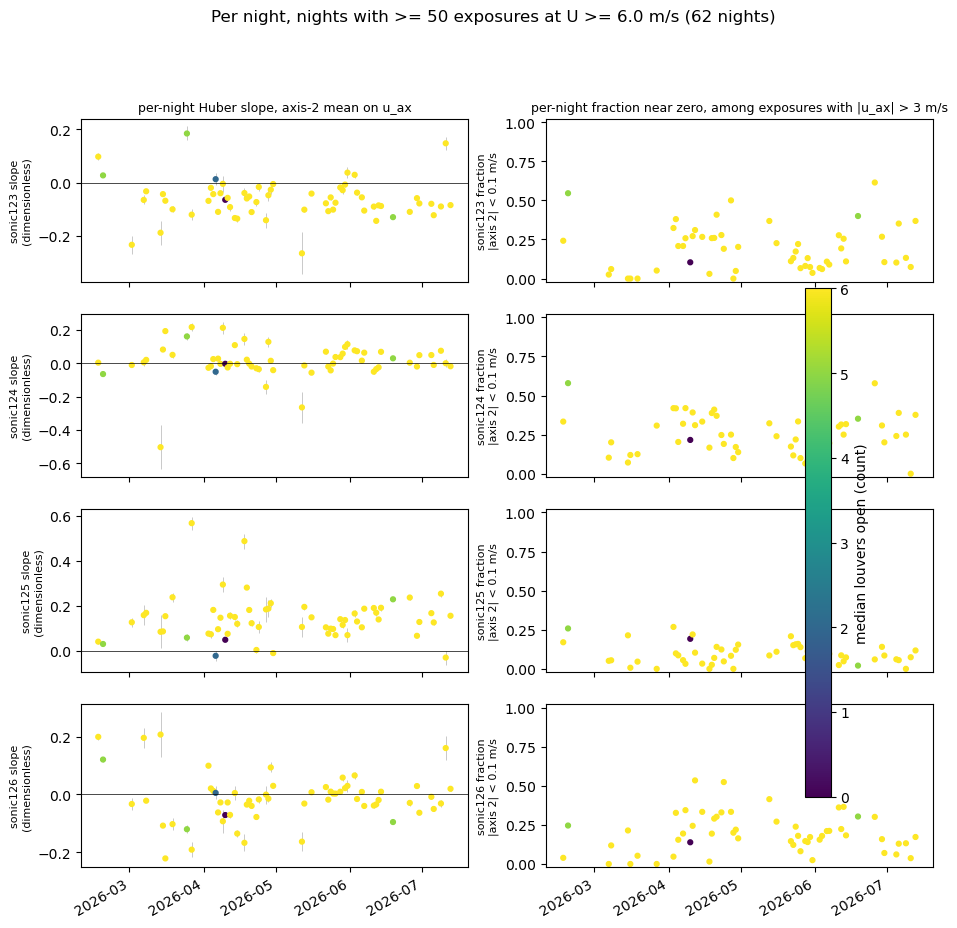

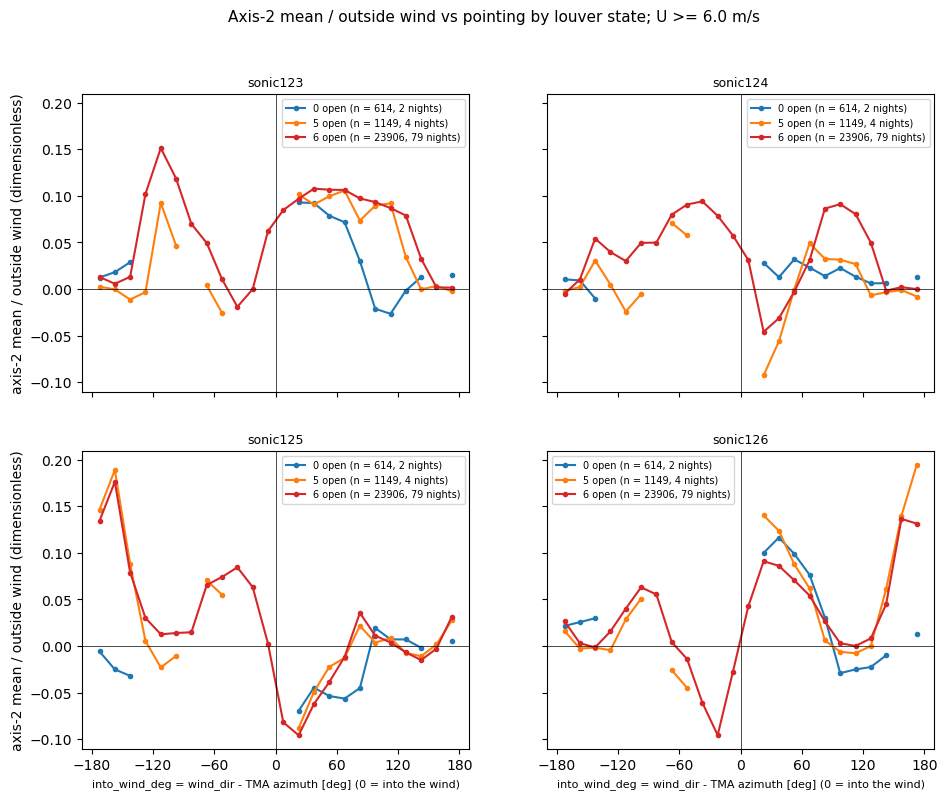

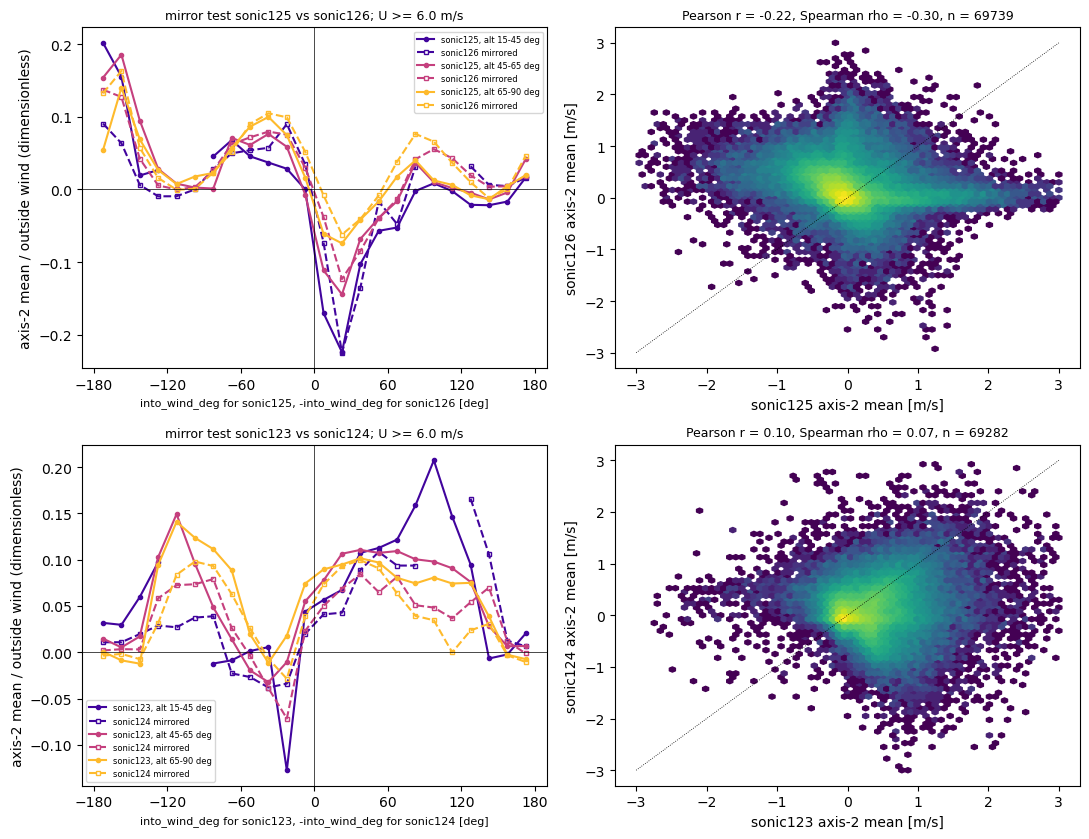

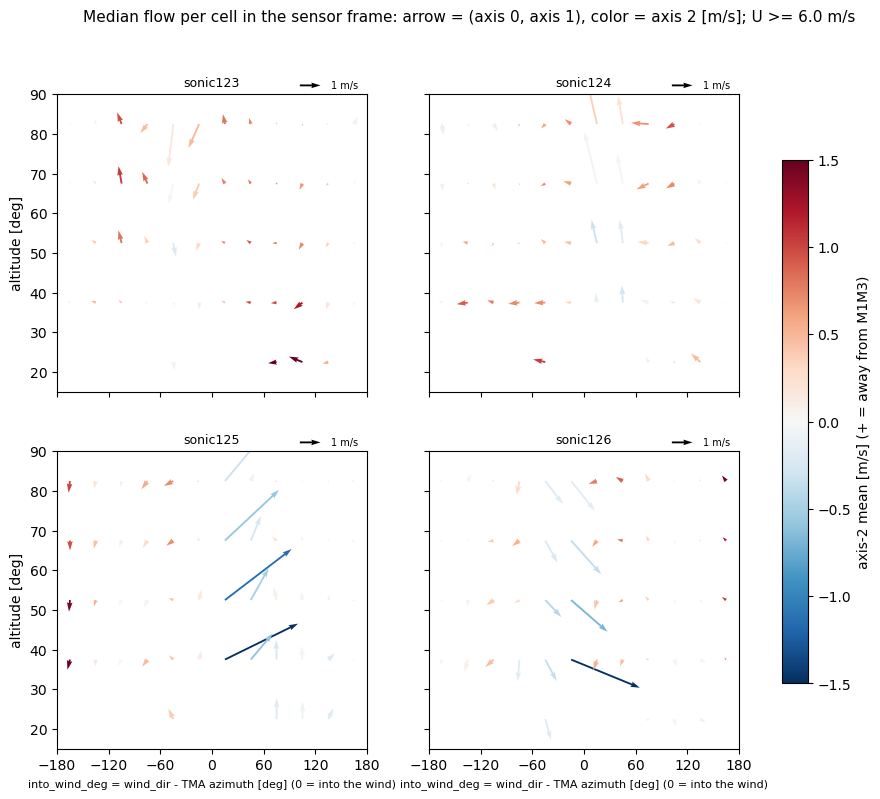

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/airflow/airflow_correlations/20261105_wind_vs_sonic_v3/wind_vs_sonic_v3.pdf


In [6]:
te = np.arange(-180, 181, ANGLE_STEP)
ae = np.arange(15, 91, ALT_STEP)
xt = np.arange(-180, 181, 60)
pdf = PdfPages(PDF)
XL = 'into_wind_deg = wind_dir - TMA azimuth [deg] (0 = into the wind)'

# Page 1: summary
body = (f'{len(d)} on-sky exposures, {d.day_obs.nunique()} nights, {d.day_obs.min()}-{d.day_obs.max()}; '
        f'{len(w)} with outside wind U >= {WIND_MIN} m/s.\n'
        f'Axis 2 = optical axis, positive = away from M1M3. Toward M1M3: axis-2 mean < {TOWARD_CUT} m/s.\n'
        'u_ax = -U cos(into_wind) cos(alt) [m/s]; u_par = U cos(into_wind) [m/s]. '
        'Slopes dimensionless (axis-2 m/s per outside m/s), Huber.\n'
        'r = Pearson, rho = Spearman. n = exposures with U >= 6 m/s and sonic data.\n\n'
        + summary.round(3).to_string()
        + '\n\nLouver states (all exposures): ' + str(d.louver_state.value_counts(dropna=False).to_dict())
        + '\n\n3x3 coefficients, sensor axis mean [m/s] = const + c_ax u_ax + c_el u_el + c_az u_az '
          '(c dimensionless, e = error), all exposures:\n'
        + coef[['n', 'const_ms', 'c_ax', 'e_ax', 'c_el', 'e_el', 'c_az', 'e_az', 'resid_nmad_ms']]
          .round(3).to_string())
text_page(pdf, 'wind_vs_sonic v3: summary', body)

# Pages 2-4: heat maps of sensor mean / U, altitude vs into_wind
for a in range(3):
    zs = [map2d(w.into_wind_deg.to_numpy(), w.altitude.to_numpy(),
                (w[f'sonic{i}_mean_{a}_ms'] / w.wind_speed_ms).to_numpy(), te, ae)[0] for i in SONICS]
    vm = np.nanpercentile(np.abs(np.concatenate([z.ravel() for z in zs])), 98)
    fig, axs = four_panel(f'Sonic axis {a}' + (' (optical, + = away from M1M3)' if a == 2 else '')
                          + f' mean / outside wind, median per cell; U >= {WIND_MIN} m/s, '
                          f'cells with >= {MIN_CELL} exposures')
    for ax, i, z in zip(axs.flat, SONICS, zs):
        pc = ax.pcolormesh(te, ae, z, cmap='RdBu_r', vmin=-vm, vmax=vm)
        ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
    fig.colorbar(pc, ax=axs, label=f'axis-{a} mean / outside wind (dimensionless)', shrink=0.8)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
    pdf.savefig(fig); plt.show()

# Page 5: probability toward M1M3
fig, axs = four_panel(f'Fraction of exposures with axis-2 mean < {TOWARD_CUT} m/s (toward M1M3); '
                      f'U >= {WIND_MIN} m/s')
for ax, i in zip(axs.flat, SONICS):
    y = w[f'sonic{i}_mean_2_ms'].to_numpy()
    z, n = map2d(w.into_wind_deg.to_numpy(), w.altitude.to_numpy(),
                 np.where(np.isfinite(y), (y < TOWARD_CUT).astype(float), np.nan), te, ae, 'mean')
    pc = ax.pcolormesh(te, ae, z, cmap='magma_r', vmin=0, vmax=1)
    ax.set_title(f'sonic{i}: {np.nanmean(y < TOWARD_CUT):.2f} of {np.isfinite(y).sum()} exposures',
                 fontsize=9)
    ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
fig.colorbar(pc, ax=axs, label='fraction toward M1M3 (dimensionless)', shrink=0.8)
for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
pdf.savefig(fig); plt.show()

# Pages 6-7: onset with wind speed, low and high altitude
for lo, hi in ((15, ALT_SPLIT), (ALT_SPLIT, 90)):
    s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
    fig, axs = four_panel(f'Axis-2 mean [m/s], median per cell, vs outside wind and pointing; '
                          f'altitude {lo}-{hi} deg')
    for ax, i in zip(axs.flat, SONICS):
        z, n = map2d(s_.into_wind_deg.to_numpy(), s_.wind_speed_ms.to_numpy(),
                     s_[f'sonic{i}_mean_2_ms'].to_numpy(), te, np.array(U_EDGES))
        pc = ax.pcolormesh(te, U_EDGES, z, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
        ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.axvline(0, color='k', lw=0.5)
    fig.colorbar(pc, ax=axs, label='axis-2 mean [m/s] (+ = away from M1M3)', shrink=0.8)
    for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
    for ax in axs[:, 0]: ax.set_ylabel('outside wind speed [m/s]')
    pdf.savefig(fig); plt.show()

# Page 8: axis 2 vs u_ax with the two half-fits
fig, axs = four_panel('Axis-2 mean vs u_ax, all exposures; red/blue: Huber fits for u_ax > 0 / u_ax < 0')
for ax, i in zip(axs.flat, SONICS):
    y = d[f'sonic{i}_mean_2_ms']; ok = y.notna()
    ax.hexbin(d.u_ax[ok], y[ok], gridsize=80, bins='log', extent=(-12, 12, -3, 3), mincnt=1)
    for half, col, xx in (('u_ax>0', 'r', np.array([0, 12])), ('u_ax<0', 'b', np.array([-12, 0]))):
        r = asym[(asym.sonic == i) & (asym.alt == '15-90') & (asym.half == half)].iloc[0]
        ax.plot(xx, r.intercept_ms + r.slope * xx, col + '-', lw=1.5,
                label=f'{half}: slope {r.slope:.3f} ± {r.slope_err:.3f} (dimensionless), n = {r.n}')
    ax.axhline(TOWARD_CUT, color='k', ls=':', lw=0.8)
    ax.set_title(f'sonic{i}', fontsize=9); ax.legend(fontsize=7, loc='upper left')
for ax in axs[1]: ax.set_xlabel('u_ax = -U cos(into_wind) cos(alt) [m/s] (+ = away from M1M3)', fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('axis-2 mean [m/s]')
pdf.savefig(fig); plt.show()

# Page 9: asymmetric slopes by altitude band
body = ('Huber slope of axis-2 mean [m/s] on u_ax [m/s] (dimensionless), fitted separately for u_ax > 0 '
        'and u_ax < 0, by altitude band [deg]; all wind speeds.\n\n'
        + asym.round(3).to_string(index=False))
text_page(pdf, 'Asymmetric slopes', body)

# Page 10: bimodality by altitude band
fig, axs = plt.subplots(4, 3, figsize=(11, 11), sharex=True, sharey=True)
for r_, i in enumerate(SONICS):
    for c_, (lo, hi) in enumerate(ALT_BANDS):
        s_ = d[(d.altitude >= lo) & (d.altitude < hi)]
        y = s_[f'sonic{i}_mean_2_ms']; ok = y.notna()
        axs[r_, c_].hexbin(s_.u_ax[ok], y[ok], gridsize=60, bins='log', extent=(-12, 12, -3, 3), mincnt=1)
        axs[r_, c_].axhline(0, color='k', lw=0.4)
        axs[r_, c_].set_title(f'sonic{i}, alt {lo}-{hi} deg, n = {ok.sum()}', fontsize=8)
for ax in axs[-1]: ax.set_xlabel('u_ax [m/s] (+ = away from M1M3)')
for ax in axs[:, 0]: ax.set_ylabel('axis-2 mean [m/s]')
fig.suptitle('Axis-2 mean vs u_ax by altitude band'); fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 11: per-night slope and near-zero fraction vs day_obs
dt = pd.to_datetime(nights.day_obs.astype(str))
fig, axs = plt.subplots(4, 2, figsize=(11, 11), sharex=True)
for r_, i in enumerate(SONICS):
    sc = axs[r_, 0].scatter(dt, nights[f'slope{i}'], c=nights.louvers, cmap='viridis', vmin=0, vmax=6, s=12)
    axs[r_, 0].errorbar(dt, nights[f'slope{i}'], nights[f'err{i}'], fmt='none', ecolor='0.7', lw=0.5, zorder=0)
    axs[r_, 0].axhline(0, color='k', lw=0.5)
    axs[r_, 0].set_ylabel(f'sonic{i} slope\n(dimensionless)', fontsize=8)
    axs[r_, 1].scatter(dt, nights[f'zero{i}'], c=nights.louvers, cmap='viridis', vmin=0, vmax=6, s=12)
    axs[r_, 1].set_ylabel(f'sonic{i} fraction\n|axis 2| < 0.1 m/s', fontsize=8); axs[r_, 1].set_ylim(-0.02, 1.02)
axs[0, 0].set_title('per-night Huber slope, axis-2 mean on u_ax', fontsize=9)
axs[0, 1].set_title('per-night fraction near zero, among exposures with |u_ax| > 3 m/s', fontsize=9)
fig.colorbar(sc, ax=axs, label='median louvers open (count)', shrink=0.6)
fig.suptitle(f'Per night, nights with >= {NIGHT_MIN} exposures at U >= {WIND_MIN} m/s ({len(nights)} nights)')
fig.autofmt_xdate(); pdf.savefig(fig); plt.show()

# Page 12: louver state
lcol = {'0 open': 'tab:blue', '5 open': 'tab:orange', '6 open': 'tab:red'}
fig, axs = four_panel(f'Axis-2 mean / outside wind vs pointing by louver state; U >= {WIND_MIN} m/s')
for ax, i in zip(axs.flat, SONICS):
    for lab, col in lcol.items():
        s_ = w[w.louver_state == lab]
        c, m, n = binned_median(s_.into_wind_deg.to_numpy(),
                                (s_[f'sonic{i}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 'o-', ms=3, color=col, label=f'{lab} (n = {len(s_)}, {s_.day_obs.nunique()} nights)')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('axis-2 mean / outside wind (dimensionless)')
pdf.savefig(fig); plt.show()

# Page 13: mirror test, sonic i at +into_wind vs sonic j at -into_wind, by altitude band
acol = plt.cm.plasma(np.linspace(0.1, 0.85, len(ALT_BANDS)))
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))
for row, (i, j) in enumerate(((125, 126), (123, 124))):
    ax = axs[row, 0]
    for k, (lo, hi) in enumerate(ALT_BANDS):
        s_ = w[(w.altitude >= lo) & (w.altitude < hi)]
        c, m, _ = binned_median(s_.into_wind_deg.to_numpy(), (s_[f'sonic{i}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 'o-', ms=3, color=acol[k], label=f'sonic{i}, alt {lo}-{hi} deg')
        c, m, _ = binned_median(-s_.into_wind_deg.to_numpy(), (s_[f'sonic{j}_mean_2_ms'] / s_.wind_speed_ms).to_numpy(), te)
        ax.plot(c, m, 's--', ms=3, color=acol[k], mfc='none', label=f'sonic{j} mirrored')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5); ax.set_xticks(xt)
    ax.set_xlabel(f'into_wind_deg for sonic{i}, -into_wind_deg for sonic{j} [deg]', fontsize=8)
    ax.set_ylabel('axis-2 mean / outside wind (dimensionless)'); ax.legend(fontsize=6)
    ax.set_title(f'mirror test sonic{i} vs sonic{j}; U >= {WIND_MIN} m/s', fontsize=9)
    ax = axs[row, 1]
    ok = d[f'sonic{i}_mean_2_ms'].notna() & d[f'sonic{j}_mean_2_ms'].notna()
    xi, yj = d[f'sonic{i}_mean_2_ms'][ok], d[f'sonic{j}_mean_2_ms'][ok]
    ax.hexbin(xi, yj, gridsize=70, bins='log', extent=(-3, 3, -3, 3), mincnt=1)
    ax.plot([-3, 3], [-3, 3], 'k:', lw=0.6)
    ax.set_title(f'Pearson r = {stats.pearsonr(xi, yj)[0]:.2f}, Spearman rho = '
                 f'{stats.spearmanr(xi, yj)[0]:.2f}, n = {ok.sum()}', fontsize=9)
    ax.set_xlabel(f'sonic{i} axis-2 mean [m/s]'); ax.set_ylabel(f'sonic{j} axis-2 mean [m/s]')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 14: flow direction in the sensor frame
qt, qa = np.arange(-180, 181, 30), np.arange(15, 91, 15)
fig, axs = four_panel(f'Median flow per cell in the sensor frame: arrow = (axis 0, axis 1), color = axis 2 '
                      f'[m/s]; U >= {WIND_MIN} m/s')
for ax, i in zip(axs.flat, SONICS):
    zz = [map2d(w.into_wind_deg.to_numpy(), w.altitude.to_numpy(), w[f'sonic{i}_mean_{a}_ms'].to_numpy(),
                qt, qa)[0] for a in range(3)]
    X, Y = np.meshgrid(0.5 * (qt[1:] + qt[:-1]), 0.5 * (qa[1:] + qa[:-1]))
    q = ax.quiver(X, Y, zz[0], zz[1], zz[2], cmap='RdBu_r', clim=(-1.5, 1.5), scale=15, width=0.006)
    ax.quiverkey(q, 0.85, 1.03, 1, '1 m/s', labelpos='E', fontproperties={'size': 7})
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(xt); ax.set_xlim(-180, 180); ax.set_ylim(15, 90)
fig.colorbar(q, ax=axs, label='axis-2 mean [m/s] (+ = away from M1M3)', shrink=0.8)
for ax in axs[1]: ax.set_xlabel(XL, fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('altitude [deg]')
pdf.savefig(fig); plt.show()
pdf.close()
print(PDF)